# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.060850,12.576496,S-G1
1,1,osimertinib,B,tago-01560,-2.890198,11.729593,P
2,2,osimertinib,A,tago-02253,12.073953,13.076333,S-G1
3,3,osimertinib,A,tago-01478,15.402417,0.212805,S-syn
4,4,osimertinib,A,tago-02626,12.623246,12.740656,S-G1


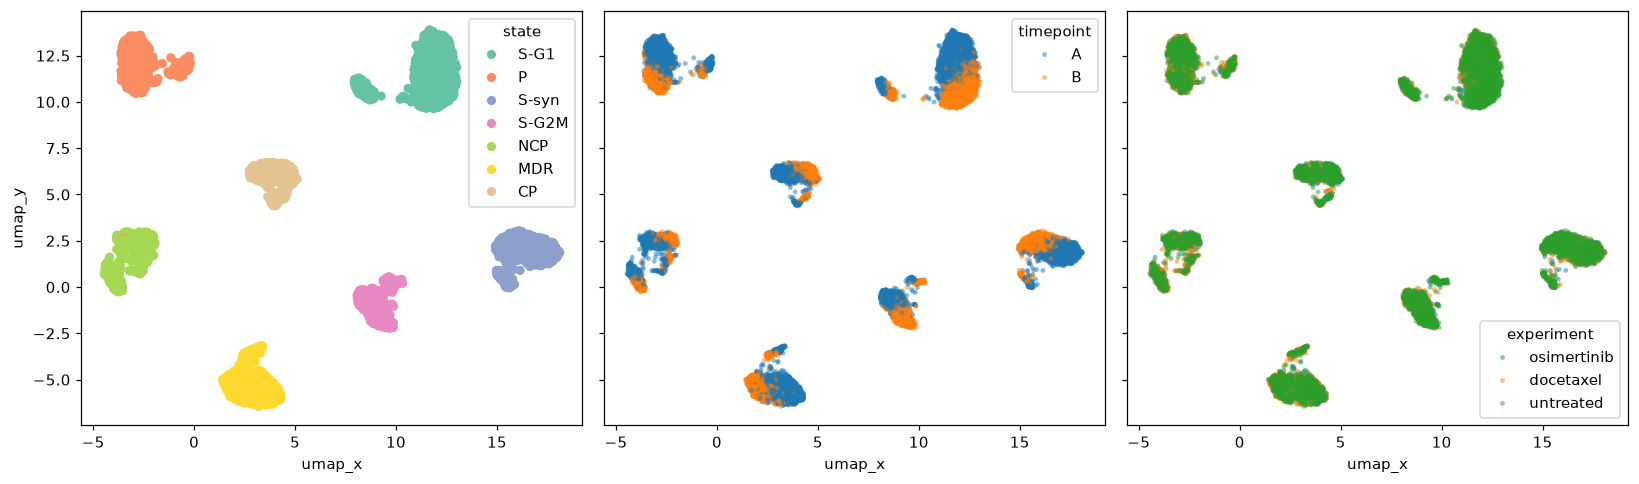

In [4]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [5]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [6]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [7]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [8]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [9]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [10]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

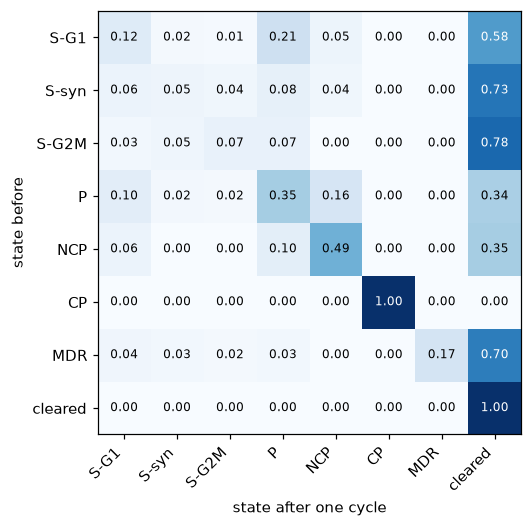

In [11]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*

Yes, CP is absorbing under osimertinib since P_hat gives CP to CP a probability of 1.0 and every other entry in the CP row is 0. In the transition counts table all 279 CP cells at time point A are still CP at time point B and none of them were cleared. No other measured state comes close to absorbing as the next largest diagonal entries are 0.490 for NCP and 0.352 for P, so cells in every other state either switch states or are cleared with substantial probability each cycle. In terms of drug response this means osimertinib neither kills CP cells nor moves them into a state it can kill so under this transition matrix any CP cells in a tumor survive every cycle of osimertinib and osimertinib alone cannot clear a tumor that contains CP cells.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

Prediction: 
Reading P_hat I predict osimertinib can eliminate tumors that start in S-G1, S-syn, S-G2M, P, NCP or MDR, but it cannot eliminate a tumor that starts in CP. Each of those six states sends some probability to cleared every cycle, from 0.338 for P up to 0.782 for S-G2M, and none of them ever moves into CP because the CP column is 0 in every row except CP's own. So with each cycle more of their probability ends up in cleared which never lets it go. CP is different since its row puts 1.0 on CP and 0 on cleared so a CP cell stays CP forever and osimertinib can never remove it. The six clearable states should only reach full clearance in the long run.

In [12]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [13]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [14]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


No, 8 rounds of osimertinib do not clear all of the cancer cells in a tumor that starts entirely in S-G1. In the above output the cleared probability rises from 0.582 after 1 cycle to 0.919 after 4 cycles and 0.989 after 8 cycles, so about 1.1% of the original cells are still alive at the end. Most of what remains is in the persister states with 0.005 in NCP and 0.003 in P after 8 cycles, compared with only 0.001 in S-G1. The cleared fraction is still rising at cycle 8 but has not reached 1 so even a course on the higher end of the typical 4 to 8 rounds leaves some cells behind.

The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

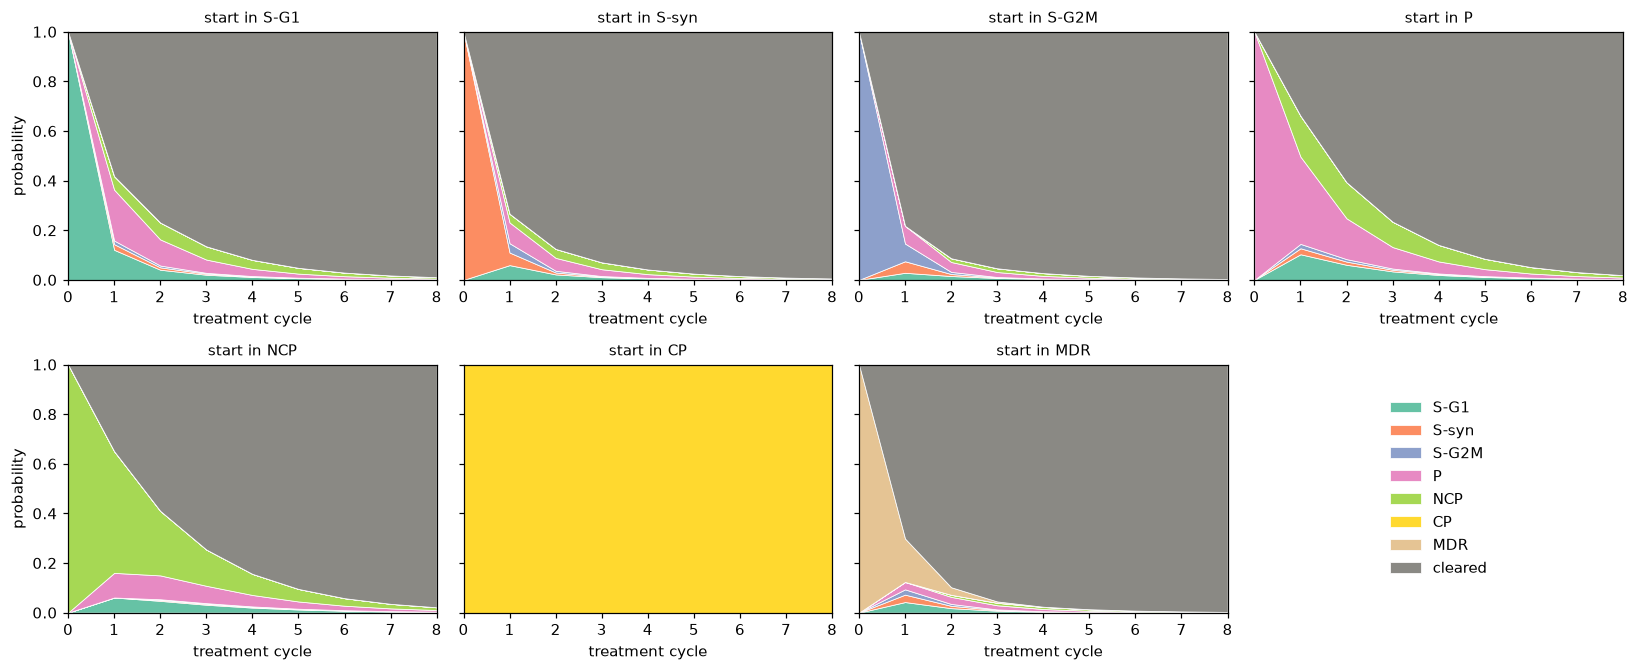

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [15]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [16]:
# Fraction of cells still alive (1 - cleared) under osimertinib, for each starting state
cleared_col = OUTCOMES.index("cleared")      # column position of "cleared" in the trajectory

rows = []
for s in STATES:
    traj_s = evolve(basis(s, P_hat), P_hat, 50)    # 50 cycles of osimertinib starting all in state s
    alive = 1 - traj_s[:, cleared_col]             # fraction alive at every cycle

    # first cycle where fewer than 1% of cells are still alive 
    cycles_to_1pct = None
    for t in range(len(alive)):
        if alive[t] < 0.01:
            cycles_to_1pct = t
            break

    # saves this starting state's results as one row
    rows.append({"start": s,
                 "alive after 3 cycles": alive[3],
                 "alive after 8 cycles": alive[8],
                 "alive after 50 cycles": alive[50],
                 "cycles until < 1% alive": cycles_to_1pct})

alive_table = pd.DataFrame(rows).set_index("start")  
alive_table.round(3)


,alive after 3 cycles,alive after 8 cycles,alive after 50 cycles,cycles until < 1% alive
start,,,,
S-G1,0.135,0.011,0.0,9.0
S-syn,0.071,0.006,0.0,7.0
S-G2M,0.047,0.004,0.0,6.0
P,0.234,0.019,0.0,10.0
NCP,0.254,0.022,0.0,10.0
CP,1.000,1.000,1.0,NaN
MDR,0.045,0.003,0.0,6.0


Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?

Osimertinib eliminates tumors that start in S-G1, S-syn, S-G2M, P, NCP and MDR since the alive fraction for each of these drops to 0.0 after 50 cycles in the alive table. The only starting state that survives is CP which still has an alive fraction of 1.000 after 3, 8 and 50 cycles so none of its cells are ever cleared. The six clearable states only approach full clearance since a tiny fraction stays alive after any finite number of cycles but it rounds to 0.0 by cycle 50.

Of the states that can be cleared, which tumor lasts the longest?

A tumor that starts in NCP lasts the longest. Both NCP and P take 10 cycles to fall below 1% alive but NCP keeps a higher alive fraction than P at every checkpoint with 0.254 compared with 0.234 after 3 cycles and 0.022 compared with 0.019 after 8 cycles.

Which starting state sticks around for the most cycles of drug?

CP sticks around for the most cycles of drug because it never falls below 1% alive which shows up as NaN in the "cycles until < 1% alive" column and its alive fraction stays at 1.000 through all 50 cycles.

Which starting state results in the highest proportion of alive cells after three cycles?

CP has the highest proportion of alive cells after three cycles at 1.000. Among the states that can be cleared NCP has the highest proportion alive after three cycles, at 0.254, followed by P at 0.234.


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

pi_mix: {'S-G1': np.float64(0.247), 'S-syn': np.float64(0.148), 'S-G2M': np.float64(0.099), 'P': np.float64(0.153), 'NCP': np.float64(0.102), 'CP': np.float64(0.097), 'MDR': np.float64(0.153), 'cleared': np.float64(0.0)}
sums to: 1.0


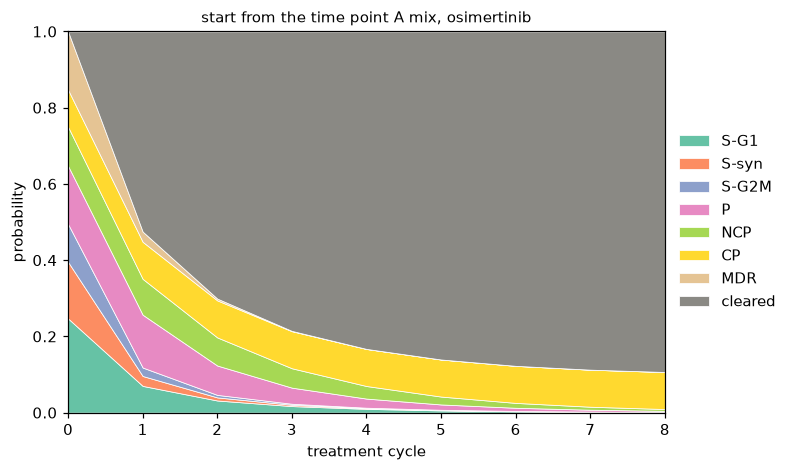

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


In [17]:
# Your code here
# Starting from a mix of cell types

# keeps only the cells at time point A from all three experiments
at_A_all = cells[cells["timepoint"] == "A"]

# counts how many time point A cells are in each state
state_counts = at_A_all["state"].value_counts()

# builds the starting vector in the same order as OUTCOMES

pi_mix = []
for s in OUTCOMES:
    if s in state_counts.index:
        pi_mix.append(state_counts[s] / len(at_A_all))   # fraction of time point A cells in state s
    else:
        pi_mix.append(0.0)                               # "cleared" has no cells at time point A
pi_mix = np.array(pi_mix)                                # numpy array, needed later by rng.choice

print("pi_mix:", dict(zip(OUTCOMES, pi_mix.round(3))))
print("sums to:", pi_mix.sum())

# evolve pi_mix and plot the results
traj_mix = evolve(pi_mix, P_hat, N_CYCLES)


fig, ax = plt.subplots(figsize=(7, 4.5))
plot_trajectory(traj_mix, ax, "start from the time point A mix, osimertinib")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()


pd.DataFrame(traj_mix, columns=OUTCOMES).round(3)


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

*Which state ends up dominating the remaining cluster?

CP ends up dominating the cells that remain. In the mixed tumor table CP stays at 0.097 in every cycle while every other alive state shrinks, so after 8 cycles CP makes up 0.097 of the 0.107 that is still alive, which is about 91% of the remaining cells. The stacked plot shows the same pattern, with the yellow CP band keeping the same height while the other colored bands thin out to almost nothing by cycle 8.

Will these cells ever be cleared?

No, the CP cells will never be cleared under osimertinib because the CP row of P_hat puts a probability of 1.0 on CP and 0 on cleared so a CP cell stays CP every cycle. The other states in the mix are all cleared in the long run as the alive table showed when each of them fell to 0.0 alive after 50 cycles.

How does the long-run endpoint relate to the transition matrix?

The long-run endpoint is set by the two absorbing states in P_hat, CP and cleared, since all of the probability eventually ends up in one of them. No other state ever moves into CP because the CP column of P_hat is 0 in every row except CP's own so the long-run CP share equals the starting CP share in pi_mix, 0.097. Everything else ends up in cleared so the tumor approaches 0.903 cleared and 0.097 CP (1 − 0.097) and the cleared fraction of 0.893 at cycle 8 is already close to that endpoint.


## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [18]:
##Add code here
def build_transition_matrix(experiment):
    
    # cells from this experiment at each time point
    exp_cells = cells[cells["experiment"] == experiment]
    exp_A = exp_cells[exp_cells.timepoint == "A"][["lineage_tag", "state"]]
    exp_B = exp_cells[exp_cells.timepoint == "B"][["lineage_tag", "state"]]

    # matchs each A cell to its B descendant, a tag missing at B means the cell was cleared
    exp_pairs = pd.merge(exp_A, exp_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    exp_pairs["state_B"] = exp_pairs["state_B"].fillna("cleared")

    # counts transitions then divide each row by its total
    exp_counts = (pd.crosstab(exp_pairs.state_A, exp_pairs.state_B)
                    .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    exp_P = exp_counts.div(exp_counts.sum(axis=1), axis=0)

    # adds the absorbing cleared row same as for osimertinib
    exp_P.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in exp_P.columns})
    return exp_counts, exp_P

# builds the docetaxel and drug holiday matrices
counts_doc, P_doc_df = build_transition_matrix("docetaxel")
counts_holiday, P_holiday_df = build_transition_matrix("untreated")

# every row should sum to 1
assert np.allclose(P_doc_df.sum(axis=1), 1), "Every docetaxel row should sum to 1."
assert np.allclose(P_holiday_df.sum(axis=1), 1), "Every holiday row should sum to 1."



# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()

P_doc = P_doc_df.to_numpy()

P_holiday = P_holiday_df.to_numpy()

print("transition counts (docetaxel):")
display(counts_doc)
print("estimated transition matrix (docetaxel, one cycle):")
display(P_doc_df.round(3))
print("transition counts (drug holiday):")
display(counts_holiday)
print("estimated transition matrix (drug holiday, one cycle):")
display(P_holiday_df.round(3))

transition counts (docetaxel):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,216,75,15,67,60,0,26,277
S-syn,22,49,60,22,14,0,0,273
S-G2M,8,7,10,6,6,0,0,247
P,43,19,10,195,35,0,7,168
NCP,24,0,1,30,139,0,7,118
CP,23,10,10,8,0,29,0,210
MDR,0,0,0,0,0,0,454,0


estimated transition matrix (docetaxel, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.293,0.102,0.020,0.091,0.082,0.0,0.035,0.376
S-syn,0.050,0.111,0.136,0.050,0.032,0.0,0.000,0.620
S-G2M,0.028,0.025,0.035,0.021,0.021,0.0,0.000,0.870
P,0.090,0.040,0.021,0.409,0.073,0.0,0.015,0.352
NCP,0.075,0.000,0.003,0.094,0.436,0.0,0.022,0.370
CP,0.079,0.034,0.034,0.028,0.000,0.1,0.000,0.724
MDR,0.000,0.000,0.000,0.000,0.000,0.0,1.000,0.000
cleared,0.000,0.000,0.000,0.000,0.000,0.0,0.000,1.000


transition counts (drug holiday):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,303,317,79,0,0,0,0,37
S-syn,41,151,228,0,0,0,0,21
S-G2M,189,33,89,0,0,0,0,20
P,182,44,24,143,20,0,1,27
NCP,54,20,0,66,139,0,0,12
CP,18,10,11,0,0,251,0,16
MDR,145,20,20,0,0,0,246,23


estimated transition matrix (drug holiday, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.412,0.431,0.107,0.000,0.000,0.00,0.000,0.050
S-syn,0.093,0.342,0.517,0.000,0.000,0.00,0.000,0.048
S-G2M,0.571,0.100,0.269,0.000,0.000,0.00,0.000,0.060
P,0.413,0.100,0.054,0.324,0.045,0.00,0.002,0.061
NCP,0.186,0.069,0.000,0.227,0.478,0.00,0.000,0.041
CP,0.059,0.033,0.036,0.000,0.000,0.82,0.000,0.052
MDR,0.319,0.044,0.044,0.000,0.000,0.00,0.542,0.051
cleared,0.000,0.000,0.000,0.000,0.000,0.00,0.000,1.000


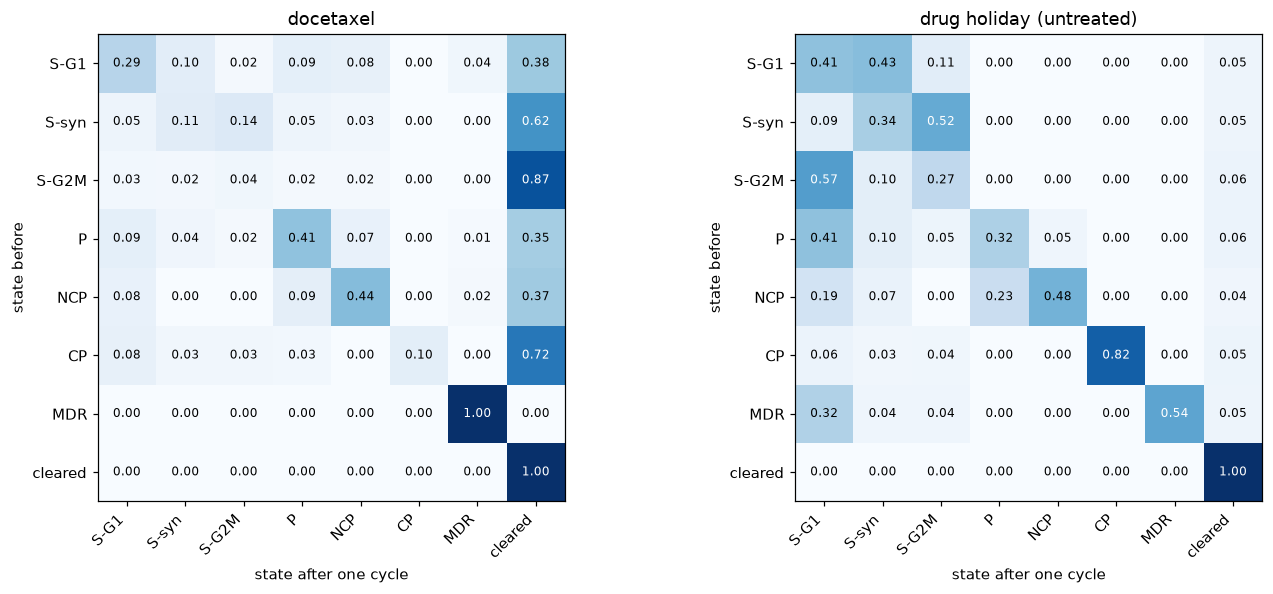

In [19]:
#Plot the transition matrices for docetaxel and the drug holiday.

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
show_matrix(P_doc_df, "docetaxel", axes[0])                    
show_matrix(P_holiday_df, "drug holiday (untreated)", axes[1])
plt.tight_layout()
plt.show()

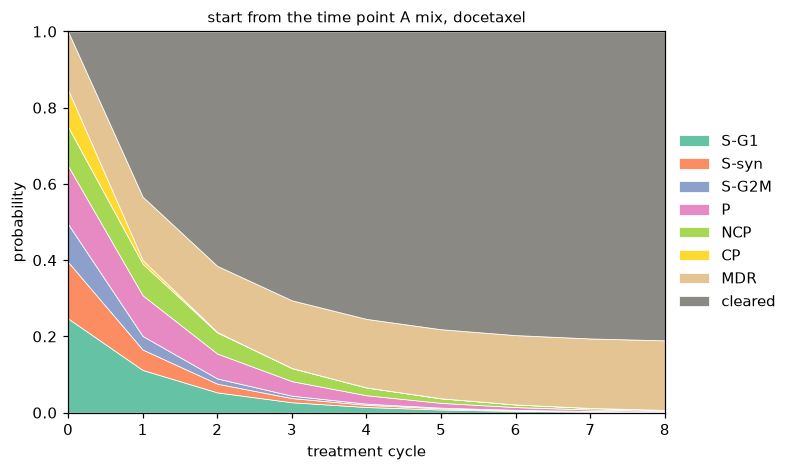

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [20]:
# Simulate the evolution of pi_mix under docetaxel 

traj_mix_doc = evolve(pi_mix, P_doc, N_CYCLES)       

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_trajectory(traj_mix_doc, ax, "start from the time point A mix, docetaxel")
ax.set_ylabel("probability")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

# table of the distribution after each cycle
pd.DataFrame(traj_mix_doc, columns=OUTCOMES).round(3)



*Answer questions in markdown here.*


What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?

The two estimated matrices are printed in the code cell above and shown as heatmaps in the plot cell. Under docetaxel MDR is absorbing since all 454 MDR cells at time point A are still MDR at time point B, giving MDR to MDR a probability of 1.000 and MDR to cleared a probability of 0. This is the reverse of osimertinib where CP was absorbing and MDR was cleared with probability 0.701, while under docetaxel CP is cleared with probability 0.724 and stays CP with probability only 0.1. Docetaxel also sends a small share of S-G1, P and NCP cells into MDR (0.035, 0.015 and 0.022), whereas under osimertinib no other state ever moved into MDR.

Under the drug holiday cleared is the only absorbing state as every measured state is cleared with a probability between 0.041 and 0.061 and no measured state stays put with probability near 1, the highest diagonal entries being 0.82 for CP and 0.542 for MDR. Instead of being cleared cells mostly move among the sensitive states with S-G1 going to S-syn at 0.431, S-syn going to S-G2M at 0.517 and S-G2M going back to S-G1 at 0.571 and P and MDR cells return to S-G1 with probabilities of 0.413 and 0.319.

Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

After 8 cycles of docetaxel the mixed tumor is 0.810 cleared which is less than the 0.893 cleared under osimertinib, and nearly all of the cells left alive are MDR. CP disappears quickly falling from 0.097 to 0.000 by cycle 3 but MDR grows from 0.153 at the start to 0.183 after 8 cycles, so MDR makes up 0.183 of the 0.190 still alive, or about 96% of the remaining cells. MDR grows because other states keep feeding into it while none of its cells leave so these cells will never be cleared by docetaxel.



## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

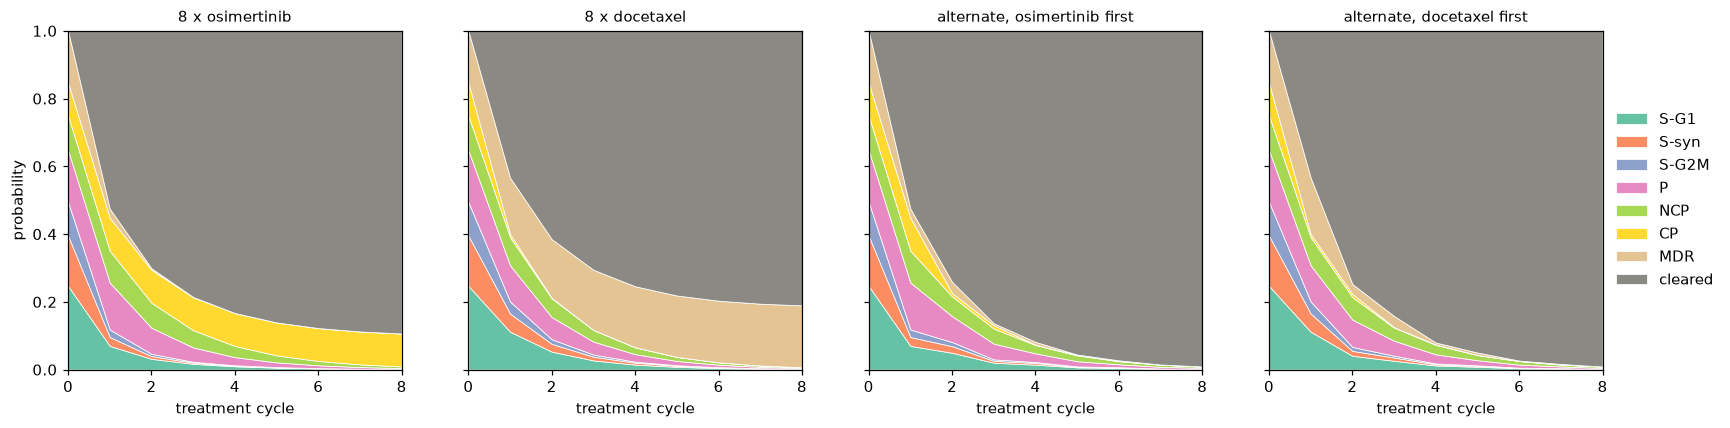

mixed tumor after 8 cycles:


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
schedule,,,,,,,,
8 x osimertinib,0.001,0.000,0.0,0.003,0.005,0.097,0.000,0.893
8 x docetaxel,0.002,0.001,0.0,0.002,0.002,0.000,0.183,0.810
"alternate, osimertinib first",0.002,0.001,0.0,0.003,0.003,0.000,0.001,0.991
"alternate, docetaxel first",0.001,0.000,0.0,0.003,0.004,0.000,0.000,0.991


In [21]:
## Add code here

# the three one-cycle transition matrices looked up by a one-letter code
DRUGS = {"O": P_osi, "D": P_doc, "H": P_holiday}

def evolve_schedule(pi0, schedule):
    
    traj = [np.asarray(pi0, dtype=float)]          # row 0 is the starting distribution
    for letter in schedule:
        traj.append(traj[-1] @ DRUGS[letter])      # one cycle of the drug named by this letter
    return np.array(traj)

cleared_col = OUTCOMES.index("cleared")            # column position of cleared



#schedules
schedules = {"8 x osimertinib": "OOOOOOOO",
             "8 x docetaxel": "DDDDDDDD",
             "alternate, osimertinib first": "ODODODOD",
             "alternate, docetaxel first": "DODODODO"}



fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
mix_rows = []
for ax, (name, schedule) in zip(axes, schedules.items()):
    traj_s = evolve_schedule(pi_mix, schedule)     # evolves the mixed tumor under this schedule
    plot_trajectory(traj_s, ax, name)
    row = dict(zip(OUTCOMES, traj_s[-1]))          # distribution after the last cycle
    row["schedule"] = name
    mix_rows.append(row)
axes[0].set_ylabel("probability")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

print("mixed tumor after 8 cycles:")
display(pd.DataFrame(mix_rows).set_index("schedule").round(3))


In [22]:
# O = osimertinib, D = docetaxel, H = drug holiday
test_schedules = {"O x8": "OOOOOOOO",
                  "D x8": "DDDDDDDD",
                  "OD x4": "ODODODOD",
                  "DO x4": "DODODODO",
                  "OH x4": "OHOHOHOH",
                  "DH x4": "DHDHDHDH"}

starts = {}
for s in STATES:
    starts["all " + s] = basis(s, P_hat)           # tumor made entirely of state s
starts["measured mix"] = pi_mix                     # tumor with the time point A mix

alive_rows = []
cycles_rows = []
for start_name, pi0 in starts.items():
    alive_row = {"start": start_name}
    cycles_row = {"start": start_name}
    for sched_name, schedule in test_schedules.items():
        traj_s = evolve_schedule(pi0, schedule)
        alive = 1 - traj_s[:, cleared_col]         # fraction alive after each cycle 
        alive_row[sched_name] = alive[-1]          # fraction alive after all 8 cycles

        # first cycle where fewer than 1% of cells are alive
        first_cycle = np.nan
        for t in range(len(alive)):
            if alive[t] < 0.01:
                first_cycle = t
                break
        cycles_row[sched_name] = first_cycle
    alive_rows.append(alive_row)
    cycles_rows.append(cycles_row)

print("fraction alive after 8 cycles:")
display(pd.DataFrame(alive_rows).set_index("start").round(3))
print("first cycle with fewer than 1% alive (NaN = not within 8 cycles):")
display(pd.DataFrame(cycles_rows).set_index("start"))


fraction alive after 8 cycles:


,O x8,D x8,OD x4,DO x4,OH x4,DH x4
start,,,,,,
all S-G1,0.011,0.073,0.010,0.011,0.030,0.066
all S-syn,0.006,0.012,0.005,0.005,0.018,0.033
all S-G2M,0.004,0.006,0.003,0.002,0.013,0.012
all P,0.019,0.055,0.017,0.015,0.054,0.077
all NCP,0.022,0.068,0.019,0.017,0.068,0.090
all CP,1.000,0.010,0.006,0.004,0.568,0.019
all MDR,0.003,1.000,0.005,0.007,0.014,0.311
measured mix,0.107,0.190,0.009,0.009,0.084,0.093


first cycle with fewer than 1% alive (NaN = not within 8 cycles):


,O x8,D x8,OD x4,DO x4,OH x4,DH x4
start,,,,,,
all S-G1,NaN,NaN,8.0,NaN,NaN,NaN
all S-syn,7.0,NaN,7.0,7.0,NaN,NaN
all S-G2M,6.0,6.0,6.0,6.0,NaN,NaN
all P,NaN,NaN,NaN,NaN,NaN,NaN
all NCP,NaN,NaN,NaN,NaN,NaN,NaN
all CP,NaN,NaN,8.0,7.0,NaN,NaN
all MDR,6.0,NaN,7.0,8.0,NaN,NaN
measured mix,NaN,NaN,8.0,8.0,NaN,NaN


*Answer questions here.*


1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib to an alternating drug schedule.

The alternating schedule clears far more of the mixed tumor than either drug alone. After 8 cycles, the mixed tumor is 0.893 cleared under osimertinib alone and 0.810 cleared under docetaxel alone but 0.991 cleared under either alternating schedule. Each single drug leaves behind the state that is absorbing under it with 0.097 CP left after 8 rounds of osimertinib and 0.183 MDR left after 8 rounds of docetaxel, while alternating leaves 0.000 CP and at most 0.001 MDR. Alternating works because each drug clears the state the other drug cannot since docetaxel clears CP with probability 0.724 and osimertinib clears MDR with probability 0.701, so neither resistant state can build up. The stacked plots show the same result with a yellow CP band left under osimertinib and a tan MDR band left under docetaxel, while both alternating panels are almost entirely gray by cycle 8.

2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?

No, for the measured mix it does not matter since both alternating schedules end at 0.991 cleared with 0.009 alive and both fall below 1% alive at cycle 8. The order only matters slightly for single-state tumors. A tumor of all CP falls below 1% alive at cycle 7 when docetaxel goes first compared with cycle 8 when osimertinib goes first, and a tumor of all MDR does the reverse, falling below 1% at cycle 7 when osimertinib goes first and at cycle 8 when docetaxel goes first. In both cases it helps to start with the drug that clears the dominant resistant state.

3. In what situation would a drug holiday help clear the tumor?

A drug holiday helps when a tumor is made mostly of the state that the drug in use cannot clear. For a tumor of all MDR 8 rounds of docetaxel leave 1.000 alive, but alternating docetaxel with a holiday leaves 0.311 alive, and for a tumor of all CP 8 rounds of osimertinib leave 1.000 alive, but alternating osimertinib with a holiday leaves 0.568 alive. This happens because the holiday moves cells out of these states with MDR going to S-G1 at 0.319 and CP staying CP at only 0.82, so the next round of drug can clear them. For every other starting state adding a holiday leaves more cells alive than the drug alone (for example, 0.030 compared with 0.011 for all S-G1 under osimertinib) and no holiday schedule gets any tumor below 1% alive within 8 cycles, so alternating the two drugs is always better than a holiday when both drugs are available.

**4. Treatment prescription**

| Tumor | Treatment | Rounds | Reasoning |
|---|---|---|---|
| All S-G2M | Either drug alone | 6 | Osimertinib, docetaxel and both alternating schedules all fall below 1% alive at cycle 6 |
| All MDR | Osimertinib alone | 6 | Falls below 1% alive at cycle 6 (0.003 alive after 8), while docetaxel alone never clears MDR |
| All S-syn | Osimertinib alone | 7 | Falls below 1% alive at cycle 7, the same as either alternating schedule, while docetaxel alone does not reach 1% within 8 cycles |
| All CP | Alternate, docetaxel first | 7 | Falls below 1% alive at cycle 7 (0.004 alive after 8), while osimertinib alone never clears CP |
| All S-G1 | Alternate, osimertinib first | 8 | The only tested schedule that falls below 1% alive within 8 cycles |
| Measured mix | Alternate, either drug first | 8 | Both orders fall below 1% alive at cycle 8 (0.009 alive), compared with 0.107 alive under osimertinib alone and 0.190 under docetaxel alone |
| All P or all NCP | Alternate, docetaxel first | 8 or more | No tested schedule falls below 1% alive within 8 cycles, but docetaxel first leaves the fewest alive (0.015 for P and 0.017 for NCP), and earlier osimertinib alone needed 10 cycles to fall below 1% for both |

The general pattern is to treat a tumor dominated by MDR with osimertinib and a tumor dominated by CP with docetaxel since each of those states is absorbing under the other drug. A tumor with both CP and MDR like the measured mix should be treated by alternating the two drugs, starting with the drug that clears whichever resistant state is larger. Tumors made mostly of the persister states P and NCP are the hardest to clear and need the most rounds so they should get the full 8 rounds or more of alternating therapy. A drug holiday should only be used when one drug is available and the tumor contains the state that drug cannot clear.



## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [23]:
rng = np.random.default_rng(100)

In [24]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [25]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

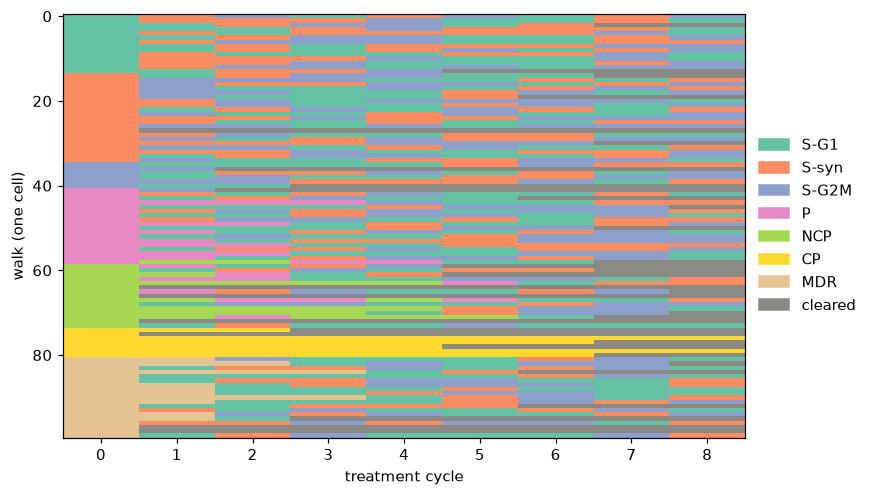

In [26]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [27]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

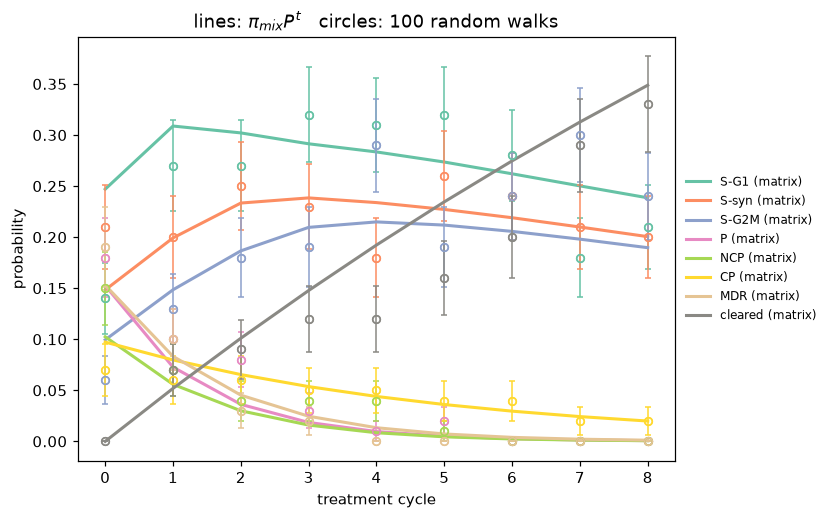

In [28]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

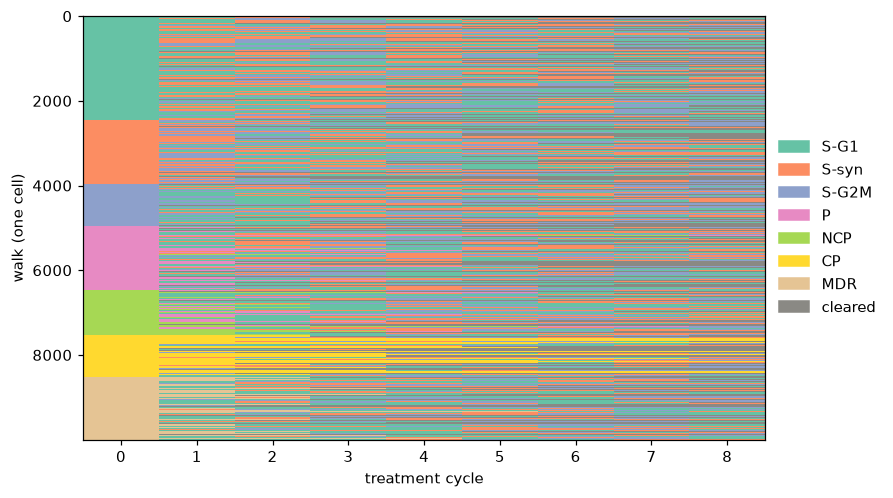

In [30]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [31]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

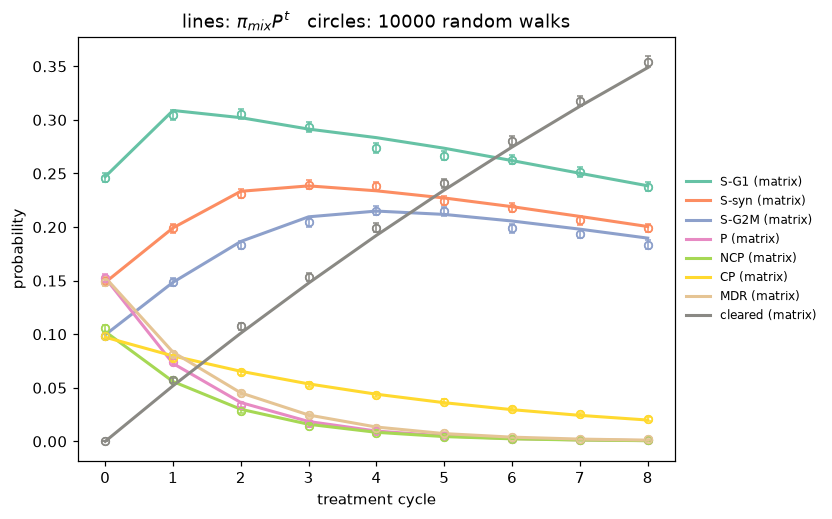

In [32]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

The gap between the circles and the lines shrinks a lot when N_WALKS goes from 100 to 10000. With 100 walks the circles scatter around the matrix lines and some miss by several hundredths, for example the cleared circle at cycle 4 sits near 0.12 while the line is near 0.19, and the error bars are wide, around plus or minus 0.04 to 0.05. With 10000 walks almost every circle sits on or right next to its line and the error bars are so small they barely show. This happens because each circle is a sample proportion, the fraction of walks in that state at that cycle and its standard error is computed in the frac and sem cell as the standard deviation divided by the square root of the number of walks. So 100 times more walks makes the standard error about 10 times smaller square. The random-walk estimate therefore converges to the exact pi_mix P^t from the matrix as the number of simulated cells grows.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [33]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

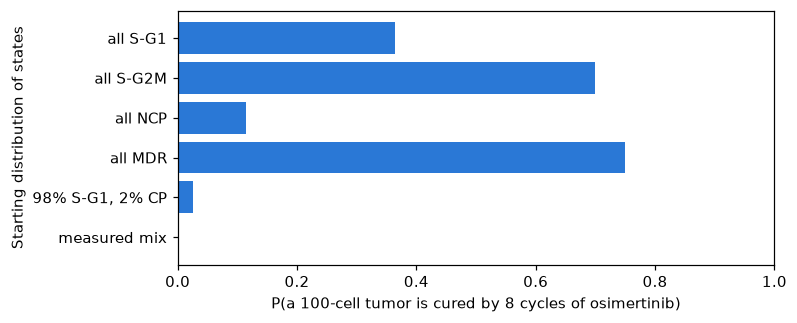

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.020,0.000
all S-G2M,0.700,0.340,0.000
all NCP,0.115,2.130,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.200,0.636
measured mix,0.000,10.690,0.919


In [34]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

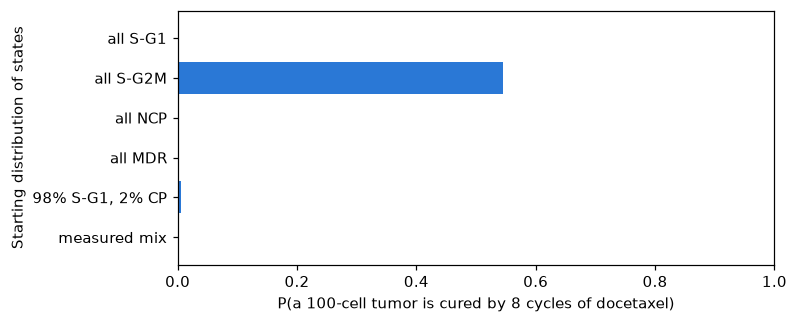

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.720,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.960,0.0
measured mix,0.000,18.960,0.0


In [35]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

Under 8 cycles of docetaxel almost no simulated tumors are cured and the results are worse than under osimertinib for every starting distribution. The only starting state with a real chance of cure is all S-G2M with a cure probability of 0.545 under docetaxel compared with 0.700 under osimertinib, while all S-G1 drops from 0.365 to 0.000, all NCP from 0.115 to 0.000, and 98% S-G1 with 2% CP from 0.025 to 0.005. The biggest change is for all MDR which goes from a cure probability of 0.750 under osimertinib to 0.000 under docetaxel with all 100.000 cells surviving on average, because MDR is absorbing under docetaxel. The measured mix is never cured under either drug but it keeps 18.960 surviving cells on average under docetaxel compared with 10.690 under osimertinib. The share of survivors that are CP is 0.0 for every start under docetaxel compared with 0.636 and 0.919 under osimertinib since docetaxel clears CP while osimertinib cannot. These averages agree with the matrix results as the mixed tumor had 0.190 alive after 8 cycles of docetaxel and 0.107 after 8 cycles of osimertinib, which matches about 19 and 11 surviving cells out of 100.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [36]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test



PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]   # state indices that count as a persister state

def make_schedule(pattern, n_cycles):
    #Repeats a pattern like "OD" until it is n_cycles letters long.
    schedule = ""
    for i in range(n_cycles):
        schedule = schedule + pattern[i % len(pattern)]   # cycle through the pattern's letters
    return schedule

def random_walk_schedule(start, schedule, rng):
    #Like random_walk but each cycle uses the matrix for that letter of the schedule
    path = [start]
    for letter in schedule:
        path.append(step(path[-1], DRUGS[letter], rng))   # one cycle of the drug named by this letter
    return path

# writes a function that runs 1000 random walks and saves them
def run_walks(pi0, schedule, n_cells, rng):
    #Simulates one tumor: n_cells random walks, each starting state drawn from pi0
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)    # starting state of every cell
    walks = []
    for s0 in starts:
        walks.append(random_walk_schedule(int(s0), schedule, rng))
    return walks

# goes through each random walk and if a persister stays for 3+ consecutive cycles we add it to tally
def becomes_PR(path, min_run=3):
    
    run = 0                                  # current streak of consecutive persister cycles
    for state in path:
        if state in PERSISTER:
            run = run + 1
            if run >= min_run:
                return True
        else:
            run = 0                          # streak broken so start counting again
    return False

#counts up cells that stayed in persister state consecutively out of total cells
def fraction_PR(walks):
    #Fraction of the cells in one tumor that become permanently resistant
    tally = 0
    for path in walks:
        if becomes_PR(path):
            tally = tally + 1
    return tally / len(walks)

# repeats for all tumors
def simulate_PR(pi0, schedule, n_tumors, n_cells, rng):
    '''PR fraction for each of n_tumors simulated tumors.'''
    fractions = []
    for tumor in range(n_tumors):
        walks = run_walks(pi0, schedule, n_cells, rng)
        fractions.append(fraction_PR(walks))
    return np.array(fractions)

N_PR_TUMORS, N_PR_CELLS = 100, 1000        # 100 tumors of 1000 cells each

# reports mean +/- SEM for osimertinib 
pr_osi = simulate_PR(pi_mix, make_schedule("O", 8), N_PR_TUMORS, N_PR_CELLS, rng)
pr_mean = pr_osi.mean()
pr_sem = np.std(pr_osi) / np.sqrt(len(pr_osi))      # same SEM formula as the random walk section

# compare to 10% threshold using 95% CI
ci_low = pr_mean - 1.96 * pr_sem
ci_high = pr_mean + 1.96 * pr_sem
print(f"osimertinib, 8 cycles: mean PR fraction = {pr_mean:.4f} +/- {pr_sem:.4f} (SEM)")
print(f"95% CI: ({ci_low:.4f}, {ci_high:.4f})")
if ci_low > 0.10:
    print("The whole CI is above 10%.")
elif ci_high < 0.10:
    print("The whole CI is below 10%.")
else:
    print("The CI contains 10%.")
print("share of tumors with more than 10% PR cells:", np.mean(pr_osi > 0.10))



osimertinib, 8 cycles: mean PR fraction = 0.1170 +/- 0.0010 (SEM)
95% CI: (0.1150, 0.1190)
The whole CI is above 10%.
share of tumors with more than 10% PR cells: 0.94


,treatment,cycles,mean PR fraction,95% CI low,95% CI high,% tumors over 10% PR
0,osimertinib alone,4,0.1105,0.1087,0.1123,84.0
1,osimertinib alone,8,0.1138,0.1118,0.1157,93.0
2,osimertinib alone,12,0.1175,0.1156,0.1194,95.0
3,osimertinib alone,16,0.1163,0.1145,0.1182,93.0
4,docetaxel alone,4,0.0858,0.0840,0.0875,5.0
5,docetaxel alone,8,0.0928,0.0908,0.0948,21.0
6,docetaxel alone,12,0.0919,0.0902,0.0935,15.0
7,docetaxel alone,16,0.0920,0.0903,0.0937,13.0
8,alternating OD,4,0.1011,0.0993,0.1030,51.0
9,alternating OD,8,0.1067,0.1047,0.1087,69.0


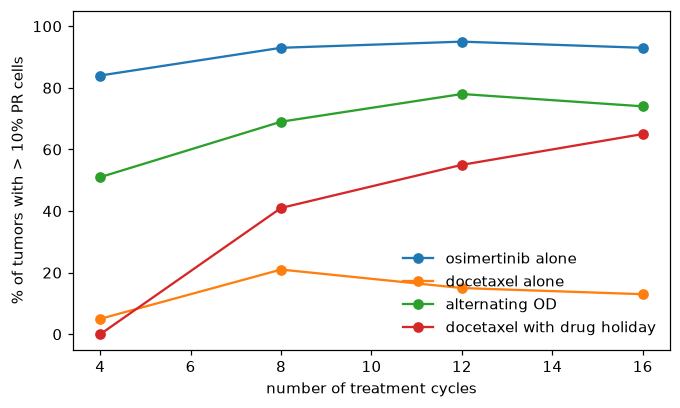

In [37]:
# What percentage of tumors have more than 10% PR cells
treatments = {"osimertinib alone": "O",
              "docetaxel alone": "D",
              "alternating OD": "OD",
              "docetaxel with drug holiday": "DH"}
cycle_counts = [4, 8, 12, 16] #how does it change with more cycles

pr_rows = []
for name, pattern in treatments.items():
    for n_cycles in cycle_counts:
        pr = simulate_PR(pi_mix, make_schedule(pattern, n_cycles), N_PR_TUMORS, N_PR_CELLS, rng)
        sem = np.std(pr) / np.sqrt(len(pr))
        pr_rows.append({"treatment": name,
                        "cycles": n_cycles,
                        "mean PR fraction": pr.mean(),
                        "95% CI low": pr.mean() - 1.96 * sem,
                        "95% CI high": pr.mean() + 1.96 * sem,
                        "% tumors over 10% PR": 100 * np.mean(pr > 0.10)})

pr_table = pd.DataFrame(pr_rows)
display(pr_table.round(4))


fig, ax = plt.subplots(figsize=(7, 4))
for name in treatments:
    sub = pr_table[pr_table["treatment"] == name]
    ax.plot(sub["cycles"], sub["% tumors over 10% PR"], "o-", label=name)
ax.set_xlabel("number of treatment cycles"); ax.set_ylabel("% of tumors with > 10% PR cells")
ax.set_ylim(-5, 105)
ax.legend(frameon=False)
plt.show()


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

Under 8 cycles of osimertinib alone the mean permanently resistant (PR) fraction across the 100 simulated tumors is 0.1170 plus or minus 0.0010 (SEM), with a 95% confidence interval from 0.1150 to 0.1190, so the whole interval is above the 10% threshold and 94% of tumors have more than 10% PR cells.

Osimertinib alone: Most tumors pass the 10% threshold under osimertinib alone with 84% of tumors over 10% PR after 4 cycles, 93% after 8, 95% after 12 and 93% after 16. The 95% confidence interval for the mean PR fraction is above 10% at every number of cycles and it is the highest of the four treatments at every cycle count.

Docetaxel alone: Docetaxel alone has the fewest tumors over 10% PR at most cycle counts with 5% after 4 cycles, 21% after 8, 15% after 12 and 13% after 16. Its 95% confidence interval is below 10% at every number of cycles as the highest upper bound is 0.0948 at 8 cycles.

Alternating OD: Alternating OD falls between the two single drugs with 51% of tumors over 10% PR after 4 cycles, 69% after 8, 78% after 12 and 74% after 16. Its 95% confidence interval contains 10% after 4 cycles (0.0993 to 0.1030) but it is entirely above 10% from 8 cycles on.

Docetaxel with drug holiday: Docetaxel with a drug holiday starts with no tumors over 10% PR after 4 cycles but climbs the fastest, reaching 41% after 8 cycles, 55% after 12 and 65% after 16. Its 95% confidence interval is below 10% after 4 and 8 cycles but moves entirely above 10% after 12 and 16 cycles.

How this changes with more cycles: For every treatment the share of tumors over 10% PR rises from 4 to 8 cycles. After that osimertinib alone, docetaxel alone and alternating OD level off or dip slightly, peaking at 12 cycles (95% and 78%) or at 8 cycles for docetaxel (21%). Docetaxel with a drug holiday is the only treatment that keeps rising through 16 cycles. This shows a trade off with Part 5 since alternating OD cleared the most cells but still leaves 69% of tumors over 10% PR after 8 cycles, while docetaxel alone cleared fewer cells but leaves only 21% of tumors over the threshold.